## Assignment 2 - Erling

### Cross-border physical flows between Norway and its interconnected countries (ENTSO-E API)

The Streamlit app's cross-border page needs: a connection selector (one of Norway's four international interconnectors), a year, a pie chart of that connection's export/import split for the year, and a line plot of monthly flow for a chosen set of months. This section builds the data those come from: raw physical flow readings fetched from ENTSO-E, written into Cassandra via Spark, read back and aggregated to monthly energy totals via Spark, and stored in MongoDB - which is what the Streamlit page actually reads from at runtime.

### Imports

In [ ]:
import sys
from pathlib import Path

# This notebook lives in notebooks/, but modules/entsoe_utils.py and modules/mongo_utils.py
# live under the project root - add the root to sys.path so those imports work regardless
# of whether the Jupyter kernel's working directory is this folder or the repo root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import os

import certifi
import matplotlib.pyplot as plt
import pandas as pd
from cassandra.cluster import Cluster
from dotenv import load_dotenv
from pymongo import MongoClient

# Java/Spark setup - same configuration already verified to work earlier in this project
os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home"
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, dayofmonth, month, sum as spark_sum, year

# modules/entsoe_utils.py holds the ENTSO-E fetch/parse helpers - the XML
# response format is involved enough (see its docstring) that it made sense to
# keep it in its own module rather than duplicate it inline here.
from modules.entsoe_utils import CONNECTIONS, fetch_connection_year_xml, parse_crossborder_xml

load_dotenv()

### Fetch raw cross-border physical flow data from ENTSO-E (2024-2025)

Fetches both directions (export = out of Norway, import = into Norway) for each of the four connections, for the last two full calendar years (2024 and 2025), per the assignment. Each reading is converted from an instantaneous MW value into actual energy (MWh) using its own duration, since the API's resolution changes partway through 2025 (hourly before April, 15-minute after).

In [10]:
YEARS = [2024, 2025]  # "last two years" per the assignment - two full calendar years
frames = []

# Pull both directions for every connection, for both years - ENTSO-E records flow
# directionally, so "export" (Norway -> partner) and "import" (partner -> Norway)
# are two separate API calls, repeated once per year.
for connection in CONNECTIONS:
    for direction in ("export", "import"):
        for fetch_year in YEARS:
            xml_text = fetch_connection_year_xml(connection, direction, fetch_year)
            parsed = parse_crossborder_xml(xml_text)
            parsed["connection"] = connection
            parsed["direction"] = direction
            frames.append(parsed)

cb_raw = pd.concat(frames, ignore_index=True)
# Convert the instantaneous MW reading into actual energy for that time step
# (duration_hours accounts for the resolution change partway through 2025).
cb_raw["energy_mwh"] = cb_raw["quantity_mw"] * cb_raw["duration_hours"]

print(cb_raw.shape)
cb_raw.head()

(467664, 8)


,timestamp,out_domain,in_domain,quantity_mw,duration_hours,connection,direction,energy_mwh
0,2024-01-01 00:00:00+00:00,10YNO-2--------T,10YDK-1--------W,0.0,1.0,NO2-DK1,export,0.0
1,2024-01-01 01:00:00+00:00,10YNO-2--------T,10YDK-1--------W,0.0,1.0,NO2-DK1,export,0.0
2,2024-01-01 02:00:00+00:00,10YNO-2--------T,10YDK-1--------W,0.0,1.0,NO2-DK1,export,0.0
3,2024-01-01 03:00:00+00:00,10YNO-2--------T,10YDK-1--------W,0.0,1.0,NO2-DK1,export,0.0
4,2024-01-01 04:00:00+00:00,10YNO-2--------T,10YDK-1--------W,0.0,1.0,NO2-DK1,export,0.0


### Write the raw readings into Cassandra via Spark

In [11]:
KEYSPACE = "entsoe"
TABLE = "crossborder_flows"

# Create the keyspace/table directly over the Cassandra driver (one-off, not something Spark needs to do)
cluster = Cluster(["127.0.0.1"])
cassandra_session = cluster.connect()
cassandra_session.execute(f"""
    CREATE KEYSPACE IF NOT EXISTS {KEYSPACE}
    WITH replication = {{'class': 'SimpleStrategy', 'replication_factor': 1}}
""")
cassandra_session.execute(f"""
    CREATE TABLE IF NOT EXISTS {KEYSPACE}.{TABLE} (
        connection text,
        direction text,
        timestamp timestamp,
        out_domain text,
        in_domain text,
        quantity_mw double,
        duration_hours double,
        energy_mwh double,
        PRIMARY KEY ((connection, direction), timestamp)
    )
""")
cluster.shutdown()

spark = (
    SparkSession.builder.appName("EntsoeCassandraApp")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

sdf = spark.createDataFrame(cb_raw)
(
    sdf.write.format("org.apache.spark.sql.cassandra")
    .options(table=TABLE, keyspace=KEYSPACE)
    .mode("append")
    .save()
)
print("Wrote", sdf.count(), "rows to Cassandra.")

26/10/27 15:19:34 WARN TaskSetManager: Stage 0 contains a task of very large size (3948 KiB). The maximum recommended task size is 1000 KiB.
26/10/27 15:19:38 WARN TaskSetManager: Stage 1 contains a task of very large size (3948 KiB). The maximum recommended task size is 1000 KiB.


Wrote 467664 rows to Cassandra.


### Read back from Cassandra via Spark and aggregate to daily totals

In [12]:
cb_spark = (
    spark.read.format("org.apache.spark.sql.cassandra")
    .options(table=TABLE, keyspace=KEYSPACE)
    .load()
)

daily = (
    cb_spark.withColumn("year", year(col("timestamp")))
    .withColumn("month", month(col("timestamp")))
    .withColumn("day", dayofmonth(col("timestamp")))
    .groupBy("connection", "direction", "year", "month", "day")
    .agg((spark_sum("energy_mwh") / 1000).alias("total_gwh"))
    .orderBy("connection", "direction", "year", "month", "day")
)

cb_daily = daily.toPandas()
cb_daily["total_gwh"] = cb_daily["total_gwh"].round(2)
spark.stop()

print(cb_daily.shape)
cb_daily.head(15)

(5856, 6)


,connection,direction,year,month,day,total_gwh
0,NO2-DE,export,2024,1,1,0.00
1,NO2-DE,export,2024,1,2,1.15
2,NO2-DE,export,2024,1,3,0.26
3,NO2-DE,export,2024,1,4,4.55
4,NO2-DE,export,2024,1,5,3.53
5,NO2-DE,export,2024,1,6,0.49
6,NO2-DE,export,2024,1,7,0.08
7,NO2-DE,export,2024,1,8,4.19
8,NO2-DE,export,2024,1,9,22.24
9,NO2-DE,export,2024,1,10,32.66


### Store the daily aggregates in MongoDB

This is the collection the Streamlit page reads from directly - Cassandra and Spark are only used to get here.

In [13]:
uri = os.environ["MONGODB_URI"]
mongo_client = MongoClient(uri, tlsCAFile=certifi.where())
db = mongo_client["ind320"]
crossborder_collection = db["crossborder_daily"]

for _, row in cb_daily.iterrows():
    crossborder_collection.update_one(
        {
            "connection": row["connection"],
            "direction": row["direction"],
            "year": int(row["year"]),
            "month": int(row["month"]),
            "day": int(row["day"]),
        },
        {"$set": {"total_gwh": float(row["total_gwh"])}},
        upsert=True,
    )

print(f"Upserted {len(cb_daily)} daily documents into MongoDB.")

Upserted 5856 daily documents into MongoDB.


### Pie chart: export vs import share of a connection's yearly flow

Like on the Streamlit page, this picks one connection and one year and shows the export/import split for that year.

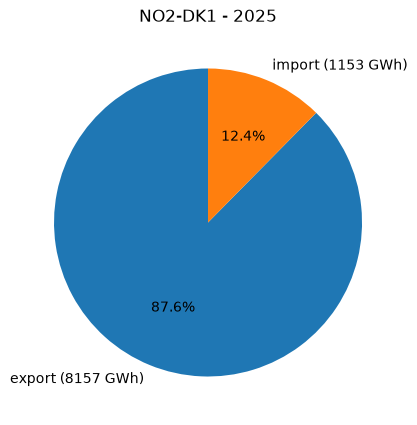

In [14]:
def plot_connection_year_pie(connection, year, ax=None):
    docs = list(crossborder_collection.find({"connection": connection, "year": year}))
    totals = pd.DataFrame(docs).groupby("direction")["total_gwh"].sum()

    ax = ax or plt.gca()
    ax.pie(
        totals.values,
        labels=[f"{d} ({v:.0f} GWh)" for d, v in totals.items()],
        autopct="%1.1f%%",
        startangle=90,
    )
    ax.set_title(f"{connection} - {year}")
    return ax


fig, ax = plt.subplots(figsize=(5, 5))
plot_connection_year_pie("NO2-DK1", 2025, ax=ax)
plt.show()

### Line plot: daily flow across a chosen set of months

Same connection/year as above; this is what the Streamlit page's `st.pills` month selector will filter down to. Aggregated daily (not monthly) so that filtering to a single month still leaves a meaningful line to plot.

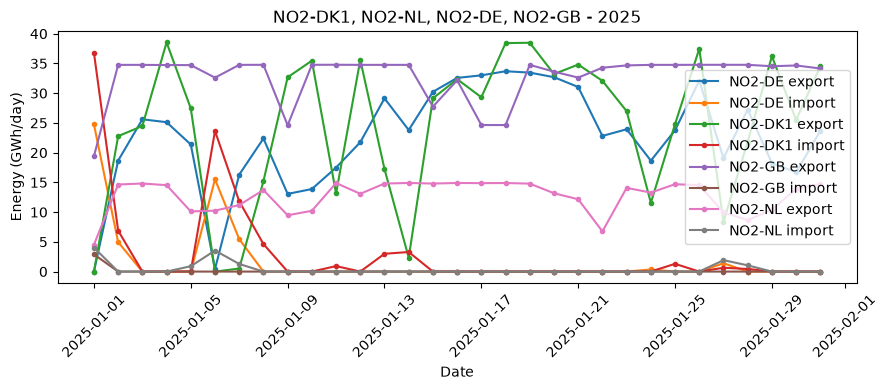

In [15]:
def plot_connection_months_line(connections, year, months, ax=None):
    """Daily line plot for the given year/months. connections can be a single
    connection key or a list of them - one line per (connection, direction)
    combination is drawn, so passing several connections shows them all
    separately, as the assignment asks for the first-month demo plot.
    """
    if isinstance(connections, str):
        connections = [connections]

    docs = list(crossborder_collection.find({
        "connection": {"$in": connections},
        "year": year,
        "month": {"$in": months},
    }))
    df = pd.DataFrame(docs)
    df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=df["day"]))
    df = df.sort_values("date")

    ax = ax or plt.gca()
    for (connection, direction), group in df.groupby(["connection", "direction"]):
        label = f"{connection} {direction}" if len(connections) > 1 else direction
        ax.plot(group["date"], group["total_gwh"], marker="o", markersize=3, label=label)

    ax.set_xlabel("Date")
    ax.set_ylabel("Energy (GWh/day)")
    ax.set_title(f"{', '.join(connections)} - {year}")
    ax.legend()
    ax.tick_params(axis="x", rotation=45)
    return ax


fig, ax = plt.subplots(figsize=(9, 4))
# First month of the year, every connection - separate line per connection and direction.
plot_connection_months_line(list(CONNECTIONS.keys()), 2025, months=[1], ax=ax)
plt.tight_layout()
plt.show()

### Work log

For Part 2, I started essentially from zero with Cassandra, Spark, and MongoDB - none of these were things I'd worked with before. Setting up the local environment took the most time: installing the right Java version, getting Docker running Cassandra, and pinning the right Spark/Cassandra connector versions so they'd actually talk to each other. MongoDB Atlas was more straightforward.

The biggest piece was the cross-border flow page. I registered for ENTSO-E API access, which required an email approval process and took a few days to come back. Once I had the token, I fetched physical flow data for Norway's four international interconnectors (to Denmark, Netherlands, Germany, and Great Britain), for both export and import directions. I learned that ENTSO-E's API only sends a data point when a value changes rather than at every timestep, so that needed careful handling when converting readings into actual energy totals. That raw data goes through Cassandra (written and read back via Spark), gets aggregated, and ends up in MongoDB, which is what the Streamlit page reads from directly.

I switched the magasinstatistikk data from a static CSV to NVE's live API, and added the EL/NO/VASS radio buttons to the Table and Plot pages so they filter by area type.

### AI Usage

For Part 2 I relied on AI more than in Part 1. A lot of new concepts and tools I hadn't worked with before, like Cassandra, Spark, and MongoDB, were made much easier by asking AI direct, hands-on questions whenever I got confused. I used it to walk me through installing and configuring all of that locally, and to write the pipeline code - fetching from ENTSO-E, writing to Cassandra via Spark, aggregating, and storing in MongoDB.

I made a point of asking it to verify things against real documentation rather than guess, especially for the ENTSO-E API itself (registration process, exact API parameters, country codes) and a couple of Streamlit widgets I hadn't used before. When something broke - and several things did - I had it look up the actual cause rather than try random fixes.

For the later fixes after peer/teacher feedback, I also used AI to help trace down the dependency-resolution issue on Streamlit Cloud (working out that uv.lock, not requirements.txt, was actually controlling the deployed install), and to think through why the plot kept breaking after switching years - which it helped me narrow down to the stray 2026 test documents rather than a logic bug.

In the end, I also used AI to check my grammar and spelling, and it made me a checklist that helped me get an overview to make sure I hadn't forgotten anything.

Link to streamlit application: https://erlinghm-ind320.streamlit.app/

Link to video: https://youtu.be/DLsVBU_fGyU

Link to github: https://github.com/Erlinghm/Erlinghm-ind320.git